# Data Loading

Extract Dataset

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/archive (1).zip"

print(zipfile.is_zipfile(zip_path))

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("imdb_data")

True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Verify Dataset


In [ ]:
import os

os.listdir("imdb_data")

['IMDB Dataset.csv']

Load Dataset

In [ ]:
import pandas as pd

df = pd.read_csv("imdb_data/IMDB Dataset.csv")

df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


# Exploratory Data Analysis (EDA)

Basic Dataset Overview

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (50000, 2)

Column Names:
Index(['review', 'sentiment'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Rows:
418


Sentiment Distribution

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


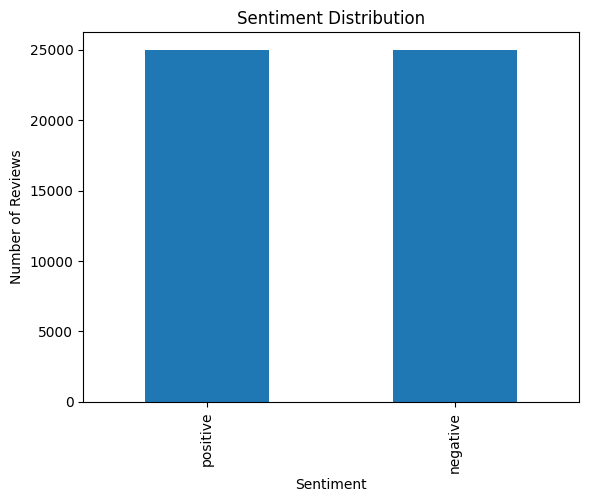

In [ ]:
import matplotlib.pyplot as plt

print(df["sentiment"].value_counts())

df["sentiment"].value_counts().plot(kind="bar")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

Review Length Analysis

count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review_length, dtype: float64


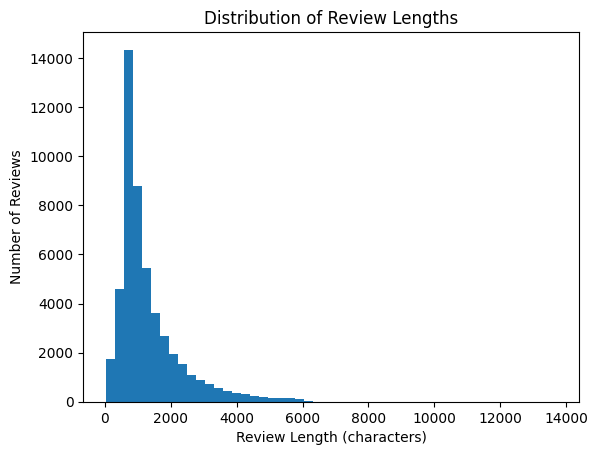

In [ ]:
df["review_length"] = df["review"].apply(len)

print(df["review_length"].describe())

plt.hist(df["review_length"], bins=50)

plt.title("Distribution of Review Lengths")
plt.xlabel("Review Length (characters)")
plt.ylabel("Number of Reviews")
plt.show()

# Data Preprocessing

Remove Duplicate  Reviews

In [ ]:
print("Before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

Before removing duplicates: (50000, 3)
After removing duplicates: (49582, 3)


Clean the Review Text

In [ ]:
import re

def clean_text(text):
    text = text.lower()                       # Convert to lowercase
    text = re.sub(r"<.*?>", " ", text)       # Remove HTML tags
    text = re.sub(r"[^a-zA-Z\s]", " ", text) # Remove special characters/numbers
    text = re.sub(r"\s+", " ", text).strip() # Remove extra spaces

    return text

df["clean_review"] = df["review"].apply(clean_text)

Comparing Original vs Cleaned Text

In [ ]:
print("ORIGINAL:")
print(df["review"].iloc[0])

print("\nCLEANED:")
print(df["clean_review"].iloc[0])


ORIGINAL:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due 

# Train and Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X = df["clean_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39665
Testing samples: 9917


# Feature Engineering


TF-IDF (Term Frequency-Inverse Document Frequency)

The vectorizer is fitted only on the training data to prevent data leakage.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (39665, 5000)
Testing shape: (9917, 5000)


#Model Training

Multinomial Naive Bayes is used to classify movie reviews as positive or negative based on their TF-IDF features.

In [ ]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

MultinomialNB()

# Model Evaluation

The trained model is evaluated on the test dataset to measure its performance on unseen movie reviews.

In [ ]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed.")

Predictions completed.


# Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8587274377331855


F1 Score
F1-score is used along with accuracy to measure how well the model balances precision and recall when classifying positive and negative reviews.

In [ ]:
from sklearn.metrics import f1_score

y_pred = model.predict(X_test_tfidf)

f1 = f1_score(y_test, y_pred, pos_label="positive")

print("Final Model Accuracy:", accuracy)
print("Final Model F1 Score:", f1)

Final Model Accuracy: 0.8587274377331855
Final Model F1 Score: 0.8619840409811841


# Classification Rport

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.87      0.84      0.86      4940
    positive       0.85      0.88      0.86      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



# Confusion Matrix

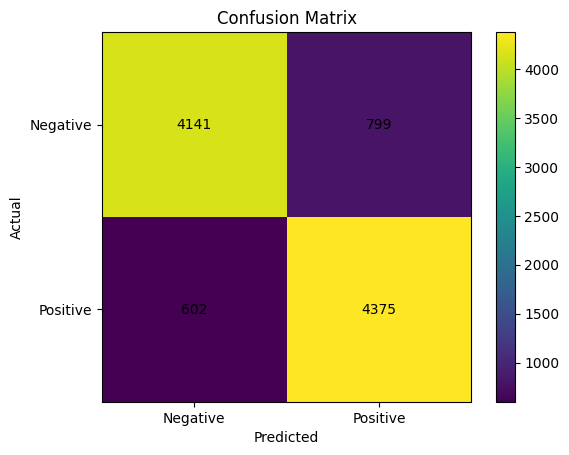

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

# Custom Review Prediction

The trained model is used to predict the sentiment of new movie reviews that were not included in the training or testing dataset.

In [ ]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)
    review_tfidf = vectorizer.transform([cleaned_review])
    prediction = model.predict(review_tfidf)[0]
    return prediction

review = "This movie was absolutely fantastic. I loved every minute of it."

print("Review:", review)
print("Predicted Sentiment:", predict_sentiment(review))

Review: This movie was absolutely fantastic. I loved every minute of it.
Predicted Sentiment: positive


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Save Model

In [ ]:
import joblib

joblib.dump(model, "/content/drive/MyDrive/movie_sentiment_model.pkl")
joblib.dump(vectorizer, "/content/drive/MyDrive/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully.")

Model and vectorizer saved successfully.


The saved model and TF-IDF vectorizer are verified to ensure that both files were successfully stored in Google Drive.

In [ ]:
import os

print(os.path.exists("/content/drive/MyDrive/movie_sentiment_model.pkl"))
print(os.path.exists("/content/drive/MyDrive/tfidf_vectorizer.pkl"))

True
True


##Final Testing

The trained sentiment classifier is tested on multiple new movie reviews to verify its predictions on different types of inputs.

In [ ]:
reviews = [
    "This movie was absolutely amazing and I loved every minute of it.",
    "The movie was boring, poorly written, and a complete waste of time.",
    "The acting was excellent and the story was very engaging.",
    "I did not enjoy this movie at all. It was disappointing."
]

for review in reviews:
    print("Review:", review)
    print("Predicted Sentiment:", predict_sentiment(review))
    print()

Review: This movie was absolutely amazing and I loved every minute of it.
Predicted Sentiment: positive

Review: The movie was boring, poorly written, and a complete waste of time.
Predicted Sentiment: negative

Review: The acting was excellent and the story was very engaging.
Predicted Sentiment: positive

Review: I did not enjoy this movie at all. It was disappointing.
Predicted Sentiment: negative



# Load Saved Model

The model and TF-IDF vectorizer that we saved earlier are loaded from Google Drive. This allows us to use the trained model again without training it from the beginning.

In [ ]:
import joblib

loaded_model = joblib.load("/content/drive/MyDrive/movie_sentiment_model.pkl")
loaded_vectorizer = joblib.load("/content/drive/MyDrive/tfidf_vectorizer.pkl")

print("Model and vectorizer loaded successfully.")

Model and vectorizer loaded successfully.


#Final Results

The sentiment analysis model was trained using TF-IDF features and Multinomial Naive Bayes. The model was evaluated on unseen test data using accuracy, classification metrics, and a confusion matrix. Additional custom reviews were also tested to verify that the trained model can make predictions on new text.

In [ ]:
print("Final Model Accuracy:", accuracy)

Final Model Accuracy: 0.8587274377331855
